# 09 · Women's win model v1: train, freeze, test on 2026-27

**What this does:**
1. **Trains** the model the EDA settled on (`docs/eda_plan_women.md`, notebooks 02-08) on all of 2025-26.
2. **Freezes** it to disk with a card of its settings and a fingerprint of the file.
3. **Tests** it on the 2026-27 games played so far, which haven't been used anywhere
   before this.

**The model:**
- **Inputs:** shots for per game, schedule-adjusted goal differential and PDO (shooting % +
  save %), each season to date and home minus away, plus the home ice switch.
- **Fitting:** L2-regularized logistic regression (C = 1), with the stat features scaled
  but not centered and no separate intercept.
- **The switch:** an evenly matched home team gets the learned home edge, and a neutral-site
  game is 50/50.

**Rules for the test (why it's trustworthy):**
- **The model is loaded back from disk before testing,** and the file's fingerprint must
  match the card. What's tested is exactly what was frozen.
- **No changes after looking.** Nothing about the model (features, C, the switch) may be
  changed because of these results. A change would be v2, trained and tested on data v1
  never saw.
- **From here on, every new 2026-27 game is also a fresh test of v1.** That's because the
  model is frozen. Rerunning this notebook later in the season just adds games to the test;
  it doesn't spend anything. The card records each run.
- **The same game rules as the EDA:** D-I games only, ties dropped, and both teams must have
  played 3 games. Features use only games before each game's date.

In [1]:
%run ./01_pregame_features.ipynb

/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:39: PerformanceWarning: DataFrame is high

All leakage checks passed.


2025-26: 696 games, 41 ties
After warm-up (both teams >= 3 GP) and dropping ties: 579 games
59 diff_ features; missing values after warm-up: 0


/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)


In [2]:
import datetime as dt
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TRAIN_SEASON, TEST_SEASON = "2025-26", "2026-27"
# Women's step 7 (notebook 08): shots for per game, schedule-adjusted goal diff, PDO
FEATURES_V1 = ["diff_shots_for_pg_season", "diff_adj_goal_diff_pg", "diff_pdo_season"]
C_V1 = 1.0
MODEL_DIR = ROOT / "models"
MODEL_PATH = MODEL_DIR / "win_model_women_v1.joblib"
CARD_PATH = MODEL_DIR / "win_model_women_v1.json"
assert SEASON == TRAIN_SEASON  # 01 built the 2025-26 tables

## 1. Train on all of 2025-26

Same construction as notebook 08: the `home_ice` column passes through unscaled as the
switch, and there's no intercept.

In [3]:
def make_model(features, C=C_V1):
    prep = ColumnTransformer([
        ("stats", StandardScaler(with_mean=False), features),  # 0 stays "evenly matched"
        ("home", "passthrough", ["home_ice"]),                   # the home ice switch
    ])
    return make_pipeline(prep, LogisticRegression(C=C, fit_intercept=False, max_iter=1000))


train = rows.reset_index(drop=True)
model = make_model(FEATURES_V1).fit(train, train["home_win"])

coef = model[-1].coef_[0]
scale = model[0].named_transformers_["stats"].scale_
even = model.predict_proba(pd.DataFrame({**{f: [0.0, 0.0] for f in FEATURES_V1}, "home_ice": [1, 0]}))[:, 1]
assert abs(even[1] - 0.5) < 1e-12  # neutral site, evenly matched -> 50/50
print(f"Trained on {len(train)} games of {TRAIN_SEASON}")
print(f"Evenly matched: home game {even[0]:.1%}, neutral site {even[1]:.1%}")
pd.DataFrame({"coefficient (per SD)": coef, "odds × per SD": np.exp(coef)},
             index=[*(f.removeprefix("diff_") for f in FEATURES_V1), "home ice switch"]).round(3)

Trained on 579 games of 2025-26
Evenly matched: home game 51.9%, neutral site 50.0%


,coefficient (per SD),odds × per SD
shots_for_pg_season,1.011,2.749
adj_goal_diff_pg,0.820,2.271
pdo_season,-0.347,0.707
home ice switch,0.077,1.080


## 2. Freeze

Save the fitted model and a card next to it:
- **`win_model_women_v1.joblib`** is the model itself. It's gitignored, like the data.
- **`win_model_women_v1.json`** is the card: features, settings, coefficients, the scaler's spreads
  (enough to recompute any prediction by hand), and the file's SHA-256 fingerprint. It holds
  no game data, so it's committed.

The model is written only if it doesn't exist yet. **A frozen model is never overwritten:**
retraining means women's v2, under a new name.

In [4]:
MODEL_DIR.mkdir(exist_ok=True)


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


if not MODEL_PATH.exists():
    joblib.dump(model, MODEL_PATH)
    card = {
        "name": "win_model_women_v1",
        "league": "women",
        "trained_on": {"season": TRAIN_SEASON, "games": int(len(train)),
                       "rules": "D-I vs D-I that season, complete box scores only, ties dropped, "
                                "both teams >= 3 games played"},
        "trained_at": dt.date.today().isoformat(),
        "features": FEATURES_V1,
        "home_ice_switch": "1 = home game, 0 = neutral site; no separate intercept",
        "model": {"type": "LogisticRegression", "penalty": "l2", "C": C_V1, "fit_intercept": False,
                  "scaling": "StandardScaler(with_mean=False) on the stat features"},
        "coefficients": {**{f: float(c) for f, c in zip(FEATURES_V1, coef)}, "home_ice": float(coef[-1])},
        "feature_scales": {f: float(s) for f, s in zip(FEATURES_V1, scale)},
        "sklearn_version": sklearn.__version__,
        "sha256": sha256(MODEL_PATH),
        "test_runs": [],
    }
    CARD_PATH.write_text(json.dumps(card, indent=2) + "\n")
    print(f"Froze {MODEL_PATH.name} (sha256 {card['sha256'][:12]}...)")
else:
    print(f"{MODEL_PATH.name} already frozen; not overwriting.")

win_model_women_v1.joblib already frozen; not overwriting.


## 3. Load the frozen model and check it

The test uses the file on disk, never the in-memory model. The fingerprint must match the
card. If the model already existed, the freshly trained one must also give the same
predictions, which confirms the 2025-26 data and features haven't changed under it.

In [5]:
card = json.loads(CARD_PATH.read_text())
assert sha256(MODEL_PATH) == card["sha256"], "model file doesn't match its card"
frozen = joblib.load(MODEL_PATH)
assert list(card["features"]) == FEATURES_V1

check = frozen.predict_proba(train)[:, 1]
assert np.allclose(check, model.predict_proba(train)[:, 1]), "2025-26 inputs changed since the freeze"
print(f"Loaded {card['name']}: trained {card['trained_at']} on {card['trained_on']['games']} games; fingerprint OK")

Loaded win_model_women_v1: trained 2026-11-27 on 579 games; fingerprint OK


## 4. The 2026-27 test set

Built with the same functions as the training data (notebook 01), for every 2026-27 game
played so far.

In [6]:
with psycopg.connect(settings.database_url) as conn:
    test_tg, test_goalies = load(conn, TEST_SEASON)
test_table = pregame_table(test_tg, test_goalies)
test = model_rows(test_table).reset_index(drop=True)
yt = test["home_win"].to_numpy()
print(f"{TEST_SEASON}: {len(test_table)} games played, {int(test_table['home_win'].isna().sum())} ties, "
      f"{len(test)} in the test after the warm-up")
print(f"Dates: {test['game_date'].min().date()} to {test['game_date'].max().date()}; "
      f"{int((test['home_ice'] == 0).sum())} neutral-site games")

2026-27: 346 games played, 18 ties, 244 in the test after the warm-up
Dates: 2026-10-02 to 2026-11-24; 1 neutral-site games


/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_45034/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)


## 5. Results

The same baselines as the EDA, both trained on 2025-26 only:
- **home win rate:** always predicts 2025-26's home win rate;
- **win % only:** "the better record wins", a one-feature model on season win %.

The 95% intervals on the improvement come from 2,000 bootstrap resamples of the test games.
They show whether the model's edge is bigger than the luck of which games happened to be
played.

In [7]:
p_model = frozen.predict_proba(test)[:, 1]
p_base = np.full(len(test), train["home_win"].mean())
wins_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[["diff_win_pct_season"]], train["home_win"])
p_wins = wins_model.predict_proba(test[["diff_win_pct_season"]])[:, 1]


def metrics(p):
    return {"log loss": log_loss(yt, p, labels=[0, 1]), "Brier": brier_score_loss(yt, p),
            "AUC": roc_auc_score(yt, p) if np.ptp(p) > 0 else 0.5, "accuracy": ((p >= 0.5) == yt).mean()}


results = pd.DataFrame({"baseline: home win rate": metrics(p_base),
                        "baseline: win % only": metrics(p_wins),
                        "women's model v1": metrics(p_model)}).T
display(results.style.format({"log loss": "{:.4f}", "Brier": "{:.4f}", "AUC": "{:.3f}", "accuracy": "{:.1%}"}))


def ll_each(p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -(yt * np.log(p) + (1 - yt) * np.log(1 - p))


rng = np.random.default_rng(0)
idx = rng.integers(0, len(test), size=(2000, len(test)))
for name, p in [("home win rate", p_base), ("win % only", p_wins)]:
    d = ll_each(p) - ll_each(p_model)  # positive = v1 better
    boot = d[idx].mean(axis=1)
    print(f"v1 vs {name}: log loss better by {d.mean():+.4f} "
          f"(95% interval {np.quantile(boot, 0.025):+.4f} to {np.quantile(boot, 0.975):+.4f})")

,log loss,Brier,AUC,accuracy
baseline: home win rate,0.6949,0.2509,0.500,51.2%
baseline: win % only,0.6209,0.2137,0.723,68.4%
women's model v1,0.6266,0.2061,0.753,70.1%


v1 vs home win rate: log loss better by +0.0682 (95% interval -0.0256 to +0.1561)
v1 vs win % only: log loss better by -0.0057 (95% interval -0.0707 to +0.0535)


### Early vs. later in the season

Every feature is season to date, so the model should get sharper as teams play more games.
The test is split by how many games the *less experienced* team had played before the game.

In [8]:
exp = np.minimum(test["home_gp"], test["away_gp"])
test_groups = pd.cut(exp, [2, 5, 8, 99], labels=["3-5 games", "6-8 games", "9+ games"])
by_exp = []
for g, sel in test.groupby(test_groups, observed=True).groups.items():
    i = test.index.get_indexer(sel)
    by_exp.append({"less experienced team had": g, "games": len(i),
                   "v1 log loss": log_loss(yt[i], p_model[i], labels=[0, 1]),
                   "home-rate log loss": log_loss(yt[i], p_base[i], labels=[0, 1]),
                   "v1 accuracy": ((p_model[i] >= 0.5) == yt[i]).mean()})
pd.DataFrame(by_exp).set_index("less experienced team had").style.format(
    {"v1 log loss": "{:.4f}", "home-rate log loss": "{:.4f}", "v1 accuracy": "{:.1%}"})

,games,v1 log loss,home-rate log loss,v1 accuracy
less experienced team had,,,,
3-5 games,65,0.8372,0.7038,58.5%
6-8 games,67,0.5463,0.6905,79.1%
9+ games,112,0.5525,0.6923,71.4%


### Calibration

Grouped by predicted probability. **On the diagonal = honest probabilities.** With this few
games, the bins are wide; the counts are shown on each point.

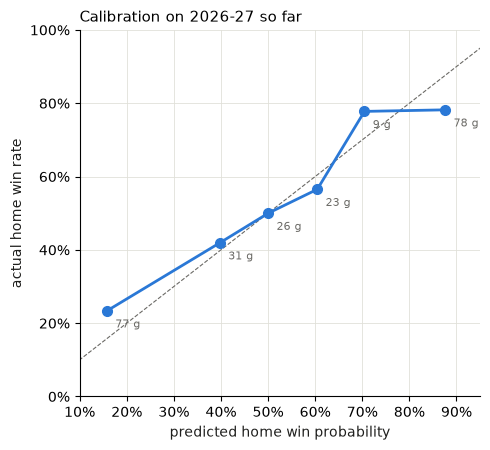

,games,predicted,actual
bin,,,
"(0.0, 0.35]",77,15.8%,23.4%
"(0.35, 0.45]",31,39.8%,41.9%
"(0.45, 0.55]",26,50.0%,50.0%
"(0.55, 0.65]",23,60.5%,56.5%
"(0.65, 0.75]",9,70.5%,77.8%
"(0.75, 1.0]",78,87.6%,78.2%


In [9]:
cal = pd.DataFrame({"p": p_model, "win": yt})
cal["bin"] = pd.cut(cal["p"], [0, 0.35, 0.45, 0.55, 0.65, 0.75, 1])
cal_t = cal.groupby("bin", observed=True).agg(games=("win", "size"), predicted=("p", "mean"), actual=("win", "mean"))

BLUE, MUTED, GRID, INK = "#2a78d6", "#6b6a66", "#e1e0d9", "#1f1f1d"
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
ax.plot(cal_t["predicted"], cal_t["actual"], "-o", color=BLUE, lw=2, ms=7)
for _, r in cal_t.iterrows():
    ax.annotate(f"{int(r['games'])} g", (r["predicted"], r["actual"]), textcoords="offset points",
                xytext=(6, -12), fontsize=8, color=MUTED)
ax.set_xlim(0.1, 0.95); ax.set_ylim(0.0, 1.0)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("predicted home win probability", color=INK)
ax.set_ylabel("actual home win rate", color=INK)
ax.set_title(f"Calibration on {TEST_SEASON} so far", loc="left", fontsize=11)
ax.grid(color=GRID, lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
cal_t.style.format({"predicted": "{:.1%}", "actual": "{:.1%}"})

## 6. Record this run on the card

Each run adds a line to the card's `test_runs`: the date, the number of test games and the
headline numbers. That keeps a history of v1 as the season fills in, and it makes it
visible if the model's performance drifts.

In [10]:
run = {"run_at": dt.date.today().isoformat(), "season": TEST_SEASON, "games": int(len(test)),
       "through": test["game_date"].max().date().isoformat(),
       "log_loss": round(float(results.loc["women's model v1", "log loss"]), 4),
       "auc": round(float(results.loc["women's model v1", "AUC"]), 3),
       "accuracy": round(float(results.loc["women's model v1", "accuracy"]), 3),
       "baseline_home_rate_log_loss": round(float(results.loc["baseline: home win rate", "log loss"]), 4),
       "baseline_win_pct_log_loss": round(float(results.loc["baseline: win % only", "log loss"]), 4)}
runs = [r for r in card["test_runs"] if r["through"] != run["through"]]  # one entry per data date
card["test_runs"] = runs + [run]
CARD_PATH.write_text(json.dumps(card, indent=2) + "\n")
pd.DataFrame(card["test_runs"])

,run_at,season,games,through,log_loss,auc,accuracy,baseline_home_rate_log_loss,baseline_win_pct_log_loss
0,2026-11-27,2026-27,244,2026-11-24,0.6266,0.753,0.701,0.6949,0.6209


## 7. The live prediction code matches this notebook

The API and dashboard don't run this notebook. They use `src/models/win_model.py`, which
recomputes each team's inputs from the database (`inputs_for`, women's rules: D-I that
season, complete box scores only) and applies the card's coefficients without scikit-learn.
**This check proves the two agree:** for every 2026-27 test game, the module's three inputs
must equal notebook 01's features, and its probability must equal the frozen model's, to
floating-point precision. If either drifts, this cell fails before anyone sees a wrong number.


In [11]:
from src.models.win_model import home_win_probability, inputs_for, load_card, spec

live_card = load_card(CARD_PATH)
pairs = spec(live_card).inputs  # card feature -> live input
max_feat, max_prob = 0.0, 0.0
with psycopg.connect(settings.database_url) as conn:
    for r, p in zip(test.itertuples(), p_model):
        both = inputs_for(conn, live_card, [r.home_id, r.away_id], TEST_SEASON, r.game_date.date())
        h, a = both[r.home_id], both[r.away_id]
        for feature, key in pairs.items():
            max_feat = max(max_feat, abs((h[key] - a[key]) - getattr(r, feature)))
        max_prob = max(max_prob, abs(home_win_probability(live_card, h, a, bool(r.home_ice)) - p))
assert max_feat < 1e-9, f"live features differ from notebook 01 by {max_feat}"
assert max_prob < 1e-9, f"live probabilities differ from the frozen model by {max_prob}"
print(f"{len(test)} games: largest feature difference {max_feat:.1e}, largest probability difference {max_prob:.1e}")


244 games: largest feature difference 8.9e-16, largest probability difference 2.2e-16


## Conclusions (first run: 2026-27 through Nov 24, 244 games)

**1. The women's v1 is frozen.** Trained on 579 games of 2025-26: shots for per game 2.75× the
odds per SD, schedule-adjusted goal differential 2.27×, PDO 0.71× (the luck correction). An
evenly matched home team wins 51.9%; a neutral-site game is 50/50. Card:
`models/win_model_women_v1.json`.

**2. On 2026-27 so far it clearly beats the home win rate, and ties "the better record wins":**

| | Log loss | AUC | Accuracy |
|---|---|---|---|
| Home win rate | 0.695 | 0.500 | 51.2% |
| Win % only | **0.621** | 0.723 | 68.4% |
| **Women's v1** | 0.627 | **0.753** | **70.1%** |

- It ranks games better than win % (AUC 0.753 vs 0.723) and picks more winners, but its log
  loss is about the same (−0.006, 95% interval −0.071 to +0.054): **no real difference yet**.
- Its edge over the home win rate is +0.068 in log loss, with an interval (−0.026 to +0.156)
  that still crosses zero, because of the early-season games (point 3).

**3. The weak spot is the first weeks: it's overconfident with only 3–5 games of history.**

| Less experienced team had | Games | v1 log loss | Home-rate log loss | v1 accuracy |
|---|---|---|---|---|
| 3–5 games | 65 | **0.837** | 0.704 | 58.5% |
| 6–8 games | 67 | 0.546 | 0.691 | 79.1% |
| 9+ games | 112 | 0.553 | 0.692 | 71.4% |

From 6 games on it's strong (log loss about 0.55, 71–79% of winners). Before that, a few
games of shots and goal differential produce extreme gaps, and the model turns them into
extreme probabilities. The calibration table shows the same thing: its 88% picks won 78%,
its 16% picks 23%.

**4. What this means:**
- **The model stays frozen.** These are the honest out-of-sample results; nothing is refit.
- **On the site, women's predictions should be marked "rough guide" until both teams have 6
  games**, not 3 (a presentation rule; it doesn't change the model).
- **The fix belongs in women's v2:** carrying last season's rating into the early weeks (the
  same plan as the men's v2) targets exactly this weakness.
